# Social network analysis of a public Facebook sample

**Research question:** what observed commenting and explicit tagging relationships appear in two Warsaw community groups during 2026?

This notebook runs offline on the frozen sample collected on 13 October 2026. Select a Python environment with `requirements.txt` installed, then run all cells in order. The results describe the observed sample; they do not estimate the complete Facebook communities.

## 1. Load the data

Read identifiers as strings so that long numeric IDs retain their exact values. Display names are labels, not join keys. Anonymous profiles retain their group scope.

In [1]:
from pathlib import Path
import sys, json
import pandas as pd
import networkx as nx
from IPython.display import display, Image
BASE = next((p for p in [Path.cwd(), Path.cwd()/"projekt"] if (p/"data/posts.csv").exists()), None)
if BASE is None:
    raise FileNotFoundError("Run the notebook from projekt or its parent directory.")
sys.path.insert(0, str(BASE))
from analysis import run_analysis, VARIANT_NAMES
tables = {name: pd.read_csv(BASE/"data"/f"{name}.csv", dtype=str, keep_default_na=False)
          for name in ["posts", "comments", "actors", "groups", "mentions", "interaction_events"]}
posts, comments, actors, groups, mentions, events = (tables[k] for k in tables)
display(pd.DataFrame({"Table":list(tables), "Records":[len(t) for t in tables.values()]}))
display(groups[["name", "study_role"]])

,Table,Records
0,posts,63
1,comments,25
2,actors,73
3,groups,7
4,mentions,5
5,interaction_events,30


,name,study_role
0,Warsaw Expat Business Community (WEBC),community
1,"Expats in Warsaw, Poland",community
2,Business in Poland.,classified_benchmark
3,Pomysł na BIZNES! Moja własna firma,promotion
4,Przedsiębiorcy Polska,archived_optional
5,"Impreza i Zabawa, to Warszawa!",weak_optional
6,Wspieraj lokalny biznes: KRAKÓW,local_business_optional


## 2. Validate identifiers and publication times

Check uniqueness, links between tables and complete exact timestamps. Publication time and collection time describe different events. A missing display name does not mean that the actor ID is missing.

In [2]:
assert posts.post_id.is_unique
assert comments.comment_id.is_unique
assert events.event_id.is_unique
assert set(comments.post_id) <= set(posts.post_id)
assert set(events.post_id) <= set(posts.post_id)
assert posts[["post_id", "author_id", "group_id", "timestamp"]].ne("").all().all()
assert comments[["comment_id", "author_id", "post_id", "timestamp"]].ne("").all().all()
publication = pd.to_datetime(posts.timestamp, utc=True)
print("Publication range (UTC):", publication.min(), "to", publication.max())
print("Missing display names:", (actors.display_name == "").sum())
print("Actor types:", actors.actor_type.value_counts().to_dict())
print("Basic validation passed.")

Publication range (UTC): 2022-03-16 07:29:54+00:00 to 2026-10-13 09:37:24+00:00
Missing display names: 3
Actor types: {'User': 66, 'GroupAnonAuthorProfile': 7}
Basic validation passed.


## 3. Define relationships and analysis variants

- **Comment:** comment author → post author. This analytical convention does not prove that the comment directly addresses the post author. No verified nested replies were collected.
- **Mention:** content author → explicitly tagged actor, using a structured identifier.
- **Participation:** actor → group, evidenced by an observed post or comment. This is not confirmed membership or friendship.

`all_sample` uses all seven groups and all publication years. `community_all` uses WEBC and Expats in Warsaw across all years. `community_2026` uses those two groups from 1 January through 13 October 2026, inclusive in Europe/Warsaw. Both a parent post and its interaction must fall within that interval.

Self-loop events remain in source tables but are removed from analytical graphs. All observed authors and interaction endpoints are retained, including isolates. An absent observed edge is not evidence of an absent real relationship.

,Variant,Posts,Comments,Mentions,Actors,Active,Isolates,Edges,Non-loop events
0,Full sample,63,25,5,73,30,43,26,27
1,Two community groups,27,9,5,31,14,17,12,13
2,Two communities: 2026,24,6,3,27,10,17,9,9


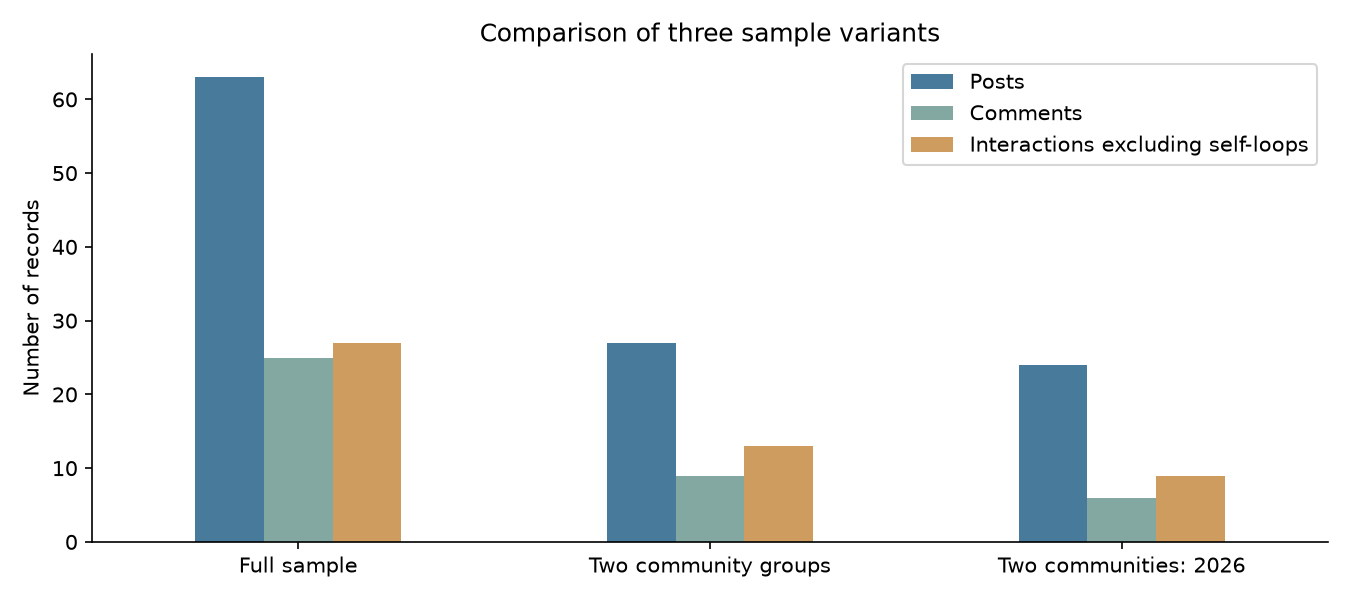

In [3]:
summary = run_analysis(BASE)
comparison = pd.DataFrame([
    {"Variant":VARIANT_NAMES[v], "Posts":x["posts"], "Comments":x["comments"],
     "Mentions":x["networks"]["mentions"]["events_raw"],
     "Actors":x["networks"]["combined"]["nodes"], "Active":x["networks"]["combined"]["active_nodes"],
     "Isolates":x["networks"]["combined"]["isolates"], "Edges":x["networks"]["combined"]["edges"],
     "Non-loop events":x["networks"]["combined"]["events_without_self_loops"]}
    for v,x in summary["variants"].items()])
display(comparison)
display(Image(filename=str(BASE/"figures/variant_comparison.png")))

## 4. Main analysis: the two community groups in 2026

The interaction graph is directed and its weights count observed events. Isolates stay in GraphML and in the density denominator. The drawing shows only active nodes. Labels A### are mapped to source identifiers in `results/node_mapping.csv`; they are pseudonyms, not irreversible anonymization. Blue nodes are served User profiles; orange nodes are group-scoped anonymous profiles.

,Measure,Value
0,Nodes,27.000000
1,Active nodes,10.000000
2,Isolates,17.000000
3,Directed edges,9.000000
4,Density including isolates,0.012821
5,Weak components,19.000000
6,Largest weak component,7.000000


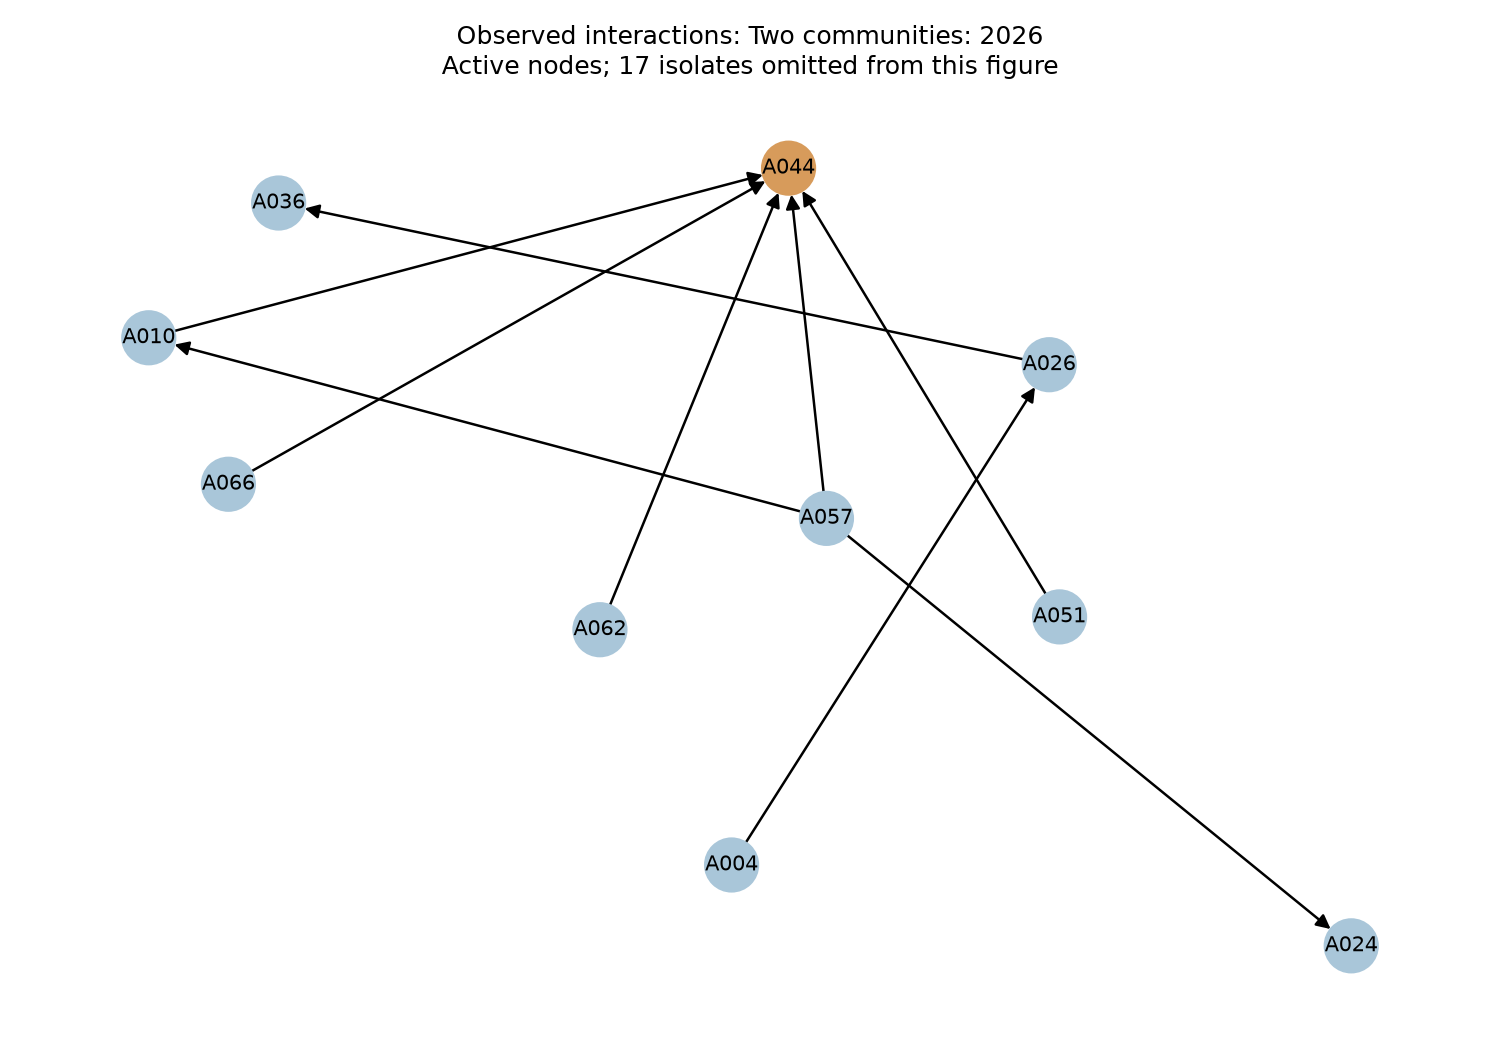

In [4]:
main_graph = nx.read_graphml(BASE/"results/community_2026_interactions.graphml")
main = summary["variants"]["community_2026"]["networks"]["combined"]
display(pd.DataFrame({"Measure":["Nodes", "Active nodes", "Isolates", "Directed edges", "Density including isolates", "Weak components", "Largest weak component"],
                     "Value":[main["nodes"],main["active_nodes"],main["isolates"],main["edges"],main["density"],main["weak_components"],main["largest_weak_component"]]}))
display(Image(filename=str(BASE/"figures/community_2026_network.png")))

## 5. Degree, strength and betweenness

In-degree counts incoming actor pairs; out-degree counts outgoing pairs. Strength counts events using edge weights. Betweenness uses directed, unweighted shortest paths and NetworkX normalization. These statistics describe this sample and do not establish social influence.

In [5]:
metrics = pd.read_csv(BASE/"results/node_metrics.csv", dtype={"node_id":str,"pseudonym":str})
main_metrics = metrics[(metrics.variant=="community_2026") & (metrics.network=="combined")].copy()
main_metrics["degree_total"] = main_metrics.in_degree + main_metrics.out_degree
main_metrics["strength_total"] = main_metrics.in_strength + main_metrics.out_strength
display(main_metrics.sort_values(["degree_total","pseudonym"],ascending=[False,True])[["pseudonym","in_degree","out_degree","in_strength","out_strength","betweenness_unweighted"]].head(10))
print("Weak component sizes:", main["weak_component_sizes"])

,pseudonym,in_degree,out_degree,in_strength,out_strength,betweenness_unweighted
383,A044,5,0,5,0,0.000000
386,A057,0,3,0,3,0.000000
369,A010,1,1,1,1,0.000000
374,A026,1,1,1,1,0.001538
367,A004,0,1,0,1,0.000000
373,A024,1,0,1,0,0.000000
378,A036,1,0,1,0,0.000000
384,A051,0,1,0,1,0.000000
389,A062,0,1,0,1,0.000000
391,A066,0,1,0,1,0.000000


Weak component sizes: [7, 3, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]


## 6. Participation and publication time

The bipartite actor-group network records observed publishing and commenting. Sharing a group does not create an inferred friendship edge. Engagement totals are snapshots; repeated observations must not be added together.

,variant,group_id,group_name,posts,comments,interaction_events
14,community_2026,2673424766123352,Warsaw Expat Business Community (WEBC),14,0,0
15,community_2026,20442701688,"Expats in Warsaw, Poland",10,6,9


Participation graph: 27 nodes and 25 actor-group pairs


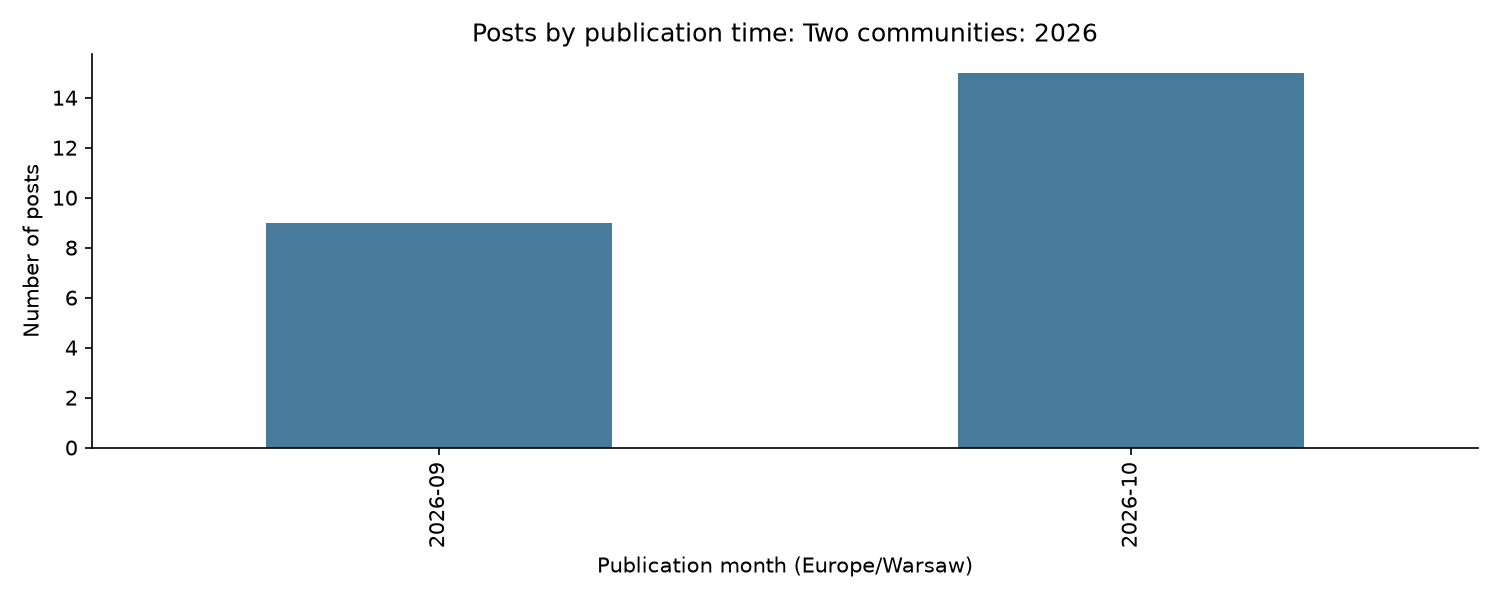

In [6]:
group_counts = pd.read_csv(BASE/"results/group_counts.csv", dtype={"group_id":str})
display(group_counts[(group_counts.variant=="community_2026") & (group_counts.posts>0)])
participation_graph = nx.read_graphml(BASE/"results/community_2026_participation.graphml")
print("Participation graph:", participation_graph.number_of_nodes(), "nodes and", participation_graph.number_of_edges(), "actor-group pairs")
display(Image(filename=str(BASE/"figures/community_2026_publications.png")))

## 7. Sensitivity to source and time selection

The full sample mixes community, advertising, local business and archived sources. Its larger graph is not a directly comparable estimate of the two Warsaw communities. Compare all three variants to see how source selection changes size, density and components.

,variant,nodes,active_nodes,isolates,edges,density,weak_components,largest_weak_component
2,all_sample,73,30,43,26,0.004947,48,13
5,community_all,31,14,17,12,0.012903,20,7
8,community_2026,27,10,17,9,0.012821,19,7


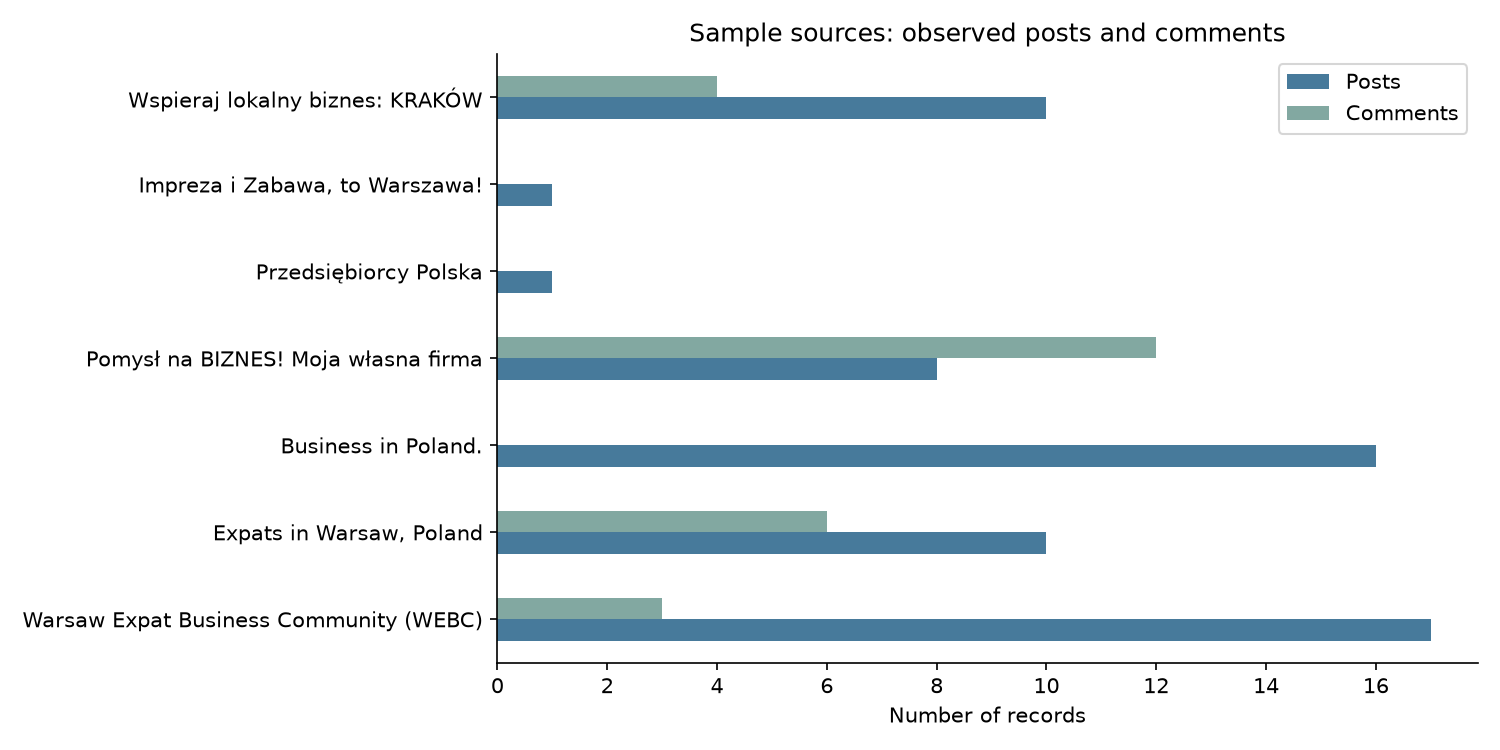

In [7]:
network_results = pd.read_csv(BASE/"results/summary_networks.csv")
display(network_results[network_results.network=="combined"][["variant","nodes","active_nodes","isolates","edges","density","weak_components","largest_weak_component"]])
display(Image(filename=str(BASE/"figures/source_counts.png")))

## 8. Conclusions and limits

This is a reproducible minimum exploratory SNA. The main variant has 27 observed actors, 9 directed actor pairs and 17 isolates. Only 10 actors participate in observed non-loop interactions. The network is too sparse and the collection too incomplete to support conclusions about whole communities.

There are no verified nested replies, complete member lists, friendship links or complete identities of reacting and sharing users. Comment visibility varies, and source selection is not random. The next collection should use a defined time window and comparable comment/reply coverage across the same groups.

Use the GraphML and CSV files in `results/` for further analysis. Read `SNA_Project_Step_by_Step.pdf` for the complete process from collection to interpretation.

In [8]:
assert all(summary["validation"].values())
assert nx.number_of_selfloops(main_graph)==0
assert sum(d["weight"] for _,_,d in main_graph.edges(data=True)) == main["events_without_self_loops"]
assert main_graph.number_of_nodes()==main["nodes"]
assert [summary["variants"][v]["networks"]["combined"]["edges"] for v in ["all_sample","community_all","community_2026"]] == [26,12,9]
print("Analysis and exports: all final checks passed.")

Analysis and exports: all final checks passed.
